**Team 1**

LSST Hack Days - Vera Rubin Observatory

Maryory Loaiza

Ver este notebook en [Colab](https://colab.research.google.com/github/ale-munozarancibia/LSST_Hackdays_Medellin_Team1_Characterizing_DIAObjects/blob/main/Project/Team1_Crossmatch_TNS_GAIA_ECDFS.ipynb)

In [1]:
pip install alerce

In [2]:
pip install pyvo

In [3]:
pip install lsdb

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyvo
import lsdb

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.table import Table, join

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 30)

print("LSDB:", lsdb.__version__)

LSDB: 0.11.0


**Campos**

In [5]:
FIELDS = {"ECDFS": (52.98, -28.12)}
FIELD = "ECDFS"
RA0, DEC0 = FIELDS[FIELD]

RADIUS_ARCSEC = 6423.0               # ~1.78 grados
radius_deg = RADIUS_ARCSEC / 3600.0

print(f"{FIELD}: RA={RA0}, Dec={DEC0}, radio={radius_deg:.3f} deg")

ECDFS: RA=52.98, Dec=-28.12, radio=1.784 deg


**Rubin desde ALeRCE (TAP)**

In [6]:
TAP_URL = "https://tap.alerce.online/tap"
tap_service = pyvo.dal.TAPService(TAP_URL)

def tap_query(query, maxrec=10_000_000):
    result = tap_service.search(query, maxrec=maxrec)
    return result.to_table().to_pandas()

tid = 1             # Rubin/LSST
sid = 1             # diaObjects
classifier_id = 3   # stamp_classifier_rubin_beta_20260421

In [7]:
query = f"""
SELECT
    *
FROM alerce_tap.object AS obj
JOIN alerce_tap.probability AS prob
    ON obj.oid = prob.oid AND obj.sid = prob.sid
JOIN alerce_tap.taxonomy AS tax
    ON prob.classifier_id = tax.classifier_id
   AND prob.class_id = tax.class_id
WHERE
    obj.tid = {tid}
    AND obj.sid = {sid}
    AND prob.classifier_id = {classifier_id}
    AND tax.class_name IN ('SN', 'AGN')
    AND prob.probability >= 0.6
    AND obj.n_det >= 50
    AND CONTAINS(POINT('ICRS', obj.meanra, obj.meandec),
                 CIRCLE('ICRS', {RA0:.7g}, {DEC0:.7g}, {radius_deg:g})) = 1
"""
df_agn_sn = tap_query(query)

print(f"diaObjects SN/AGN en {FIELD}: {len(df_agn_sn)}")
display(df_agn_sn["class_name"].value_counts())

diaObjects SN/AGN en ECDFS: 65


class_name
AGN    53
SN     12
Name: count, dtype: int64

**Tabla para Rubin**

In [8]:
RUBIN_COLS = ["oid", "meanra", "meandec", "sigmara", "sigmadec",
              "firstmjd", "lastmjd", "n_det", "class_name", "probability"]

df_rubin = (df_agn_sn[RUBIN_COLS]
            .drop_duplicates("oid")
            .reset_index(drop=True))
print(df_rubin.shape)
df_rubin.head()

(65, 10)


,oid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,n_det,class_name,probability
0,313699514821640259,51.620550,-28.114119,1.914917e-07,1.884254e-07,60989.260516,61108.032716,129,SN,0.965387
1,313677517043531799,52.372406,-28.705124,2.131295e-06,2.023052e-06,60984.251250,61088.097015,56,SN,0.981978
2,313928193953234970,54.648409,-27.699329,5.958089e-07,6.076746e-07,61041.220126,61103.036815,78,SN,0.685611
3,313853499427782700,53.677609,-29.526403,1.229188e-06,1.276612e-06,61024.144244,61069.082988,93,SN,0.869342
4,313695088894541868,52.375185,-29.338986,2.317735e-06,2.293909e-06,60988.139636,61060.119674,74,SN,0.781145


**Rubin como catálogo LSDB**

In [9]:
rubin_cat = lsdb.from_dataframe(df_rubin, ra_column="meanra", dec_column="meandec",
                                catalog_name="rubin_agn_sn")
rubin_cat

,oid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,n_det,class_name,probability
npartitions=1,,,,,,,,,,
"Order: 1, Pixel: 35",int64[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],double[pyarrow],int32[pyarrow],large_string[pyarrow],float[pyarrow]


**Catálogos externos (LSDB): TNS and GAIA DR3**

In [12]:
EXTERNAL_CATALOGS = {
    "GAIA_DR3": dict(
        url="https://data.lsdb.io/hats/gaia_dr3/gaia/",
        radius_arcsec=2.0,
        n_neighbors=1,
        suffix="_gaia",
        # Subconjunto de columnas (se usan solo las que existan). None = todas.
        columns=["designation", "source_id", "ra", "dec",
                 "w1mpro", "w1sigmpro", "w2mpro", "w2sigmpro",
                 "w3mpro", "w3sigmpro", "w4mpro", "w4sigmpro",
                 "ext_flg", "cc_flags", "ph_qual"],
    ),
    "TNS": dict(
        url="https://data.lsdb.io/hats/tns",
        radius_arcsec=2.0,
        n_neighbors=1,
        suffix="_tns",
        columns=None,   # TNS es pequeño: se conservan todas las columnas
    ),
}

cone = lsdb.ConeSearch(RA0, DEC0, radius_arcsec=RADIUS_ARCSEC)

In [13]:
def open_external(name, cfg, search_filter):
    """Open an external HATS catalog restricted to the cone,
    keeping only the requested columns that actually exist."""
    meta = lsdb.open_catalog(cfg["url"])
    info = meta.hc_structure.catalog_info
    ra_col, dec_col = info.ra_column, info.dec_column

    if cfg["columns"] is None:
        cols = None
    else:
        cols = [c for c in cfg["columns"] if c in meta.columns]
        missing = [c for c in cfg["columns"] if c not in meta.columns]
        for c in (ra_col, dec_col):
            if c not in cols:
                cols.append(c)
        if missing:
            print(f"  [{name}] columnas no encontradas (se omiten): {missing}")

    cat = lsdb.open_catalog(cfg["url"], columns=cols, search_filter=search_filter)
    print(f"{name}: RA='{ra_col}', Dec='{dec_col}', {len(cat.columns)} columnas")
    return cat, ra_col, dec_col


ext = {}
for name, cfg in EXTERNAL_CATALOGS.items():
    try:
        cat, ra_col, dec_col = open_external(name, cfg, cone)
        ext[name] = dict(cat=cat, ra=ra_col, dec=dec_col, **cfg)
    except Exception as err:
        print(f"No se pudo abrir {name} ({cfg['url']}): {type(err).__name__}: {err}")

print("\nCatálogos listos:", list(ext))

  [GAIA_DR3] columnas no encontradas (se omiten): ['w1mpro', 'w1sigmpro', 'w2mpro', 'w2sigmpro', 'w3mpro', 'w3sigmpro', 'w4mpro', 'w4sigmpro', 'ext_flg', 'cc_flags', 'ph_qual']
GAIA_DR3: RA='ra', Dec='dec', 4 columnas
TNS: RA='ra', Dec='declination', 23 columnas

Catálogos listos: ['GAIA_DR3', 'TNS']


In [14]:
# Vista rápida de cada catálogo en el campo
for name, e in ext.items():
    print(f"=== {name} ===")
    print(list(e["cat"].columns))
    display(e["cat"].head(5))

=== GAIA_DR3 ===
['designation', 'source_id', 'ra', 'dec']


Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

,designation,source_id,ra,dec
_healpix_29,,,,
2528119080246393147,Gaia DR3 5056238154588233984,5056238154588233984,53.66407,-29.788989
2528119116403281004,Gaia DR3 5056238227604442368,5056238227604442368,53.70747,-29.776626
2528119157180559573,Gaia DR3 5056238296322061056,5056238296322061056,53.682858,-29.763359
2528119437517370661,Gaia DR3 5056238846079731840,5056238846079731840,53.779056,-29.754377
2528119614031531197,Gaia DR3 5056239219740135680,5056239219740135680,53.821334,-29.743822


=== TNS ===
['objid', 'name_prefix', 'name', 'ra', 'declination', 'redshift', 'typeid', 'type', 'reporting_groupid', 'reporting_group', 'source_groupid', 'source_group', 'discoverydate', 'discoverymag', 'discmagfilter', 'filter', 'reporters', 'time_received', 'internal_names', 'Discovery_ADS_bibcode', 'Class_ADS_bibcodes', 'creationdate', 'lastmodified']


Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

,objid,name_prefix,name,ra,declination,redshift,typeid,type,reporting_groupid,reporting_group,source_groupid,source_group,discoverydate,discoverymag,discmagfilter,filter,reporters,time_received,internal_names,Discovery_ADS_bibcode,Class_ADS_bibcodes,creationdate,lastmodified
_healpix_29,,,,,,,,,,,,,,,,,,,,,,,
2530347163341259087,221789,AT,2026adyj,51.66174,-27.278248,<NA>,<NA>,<NA>,4.0,Pan-STARRS,4.0,Pan-STARRS,2026-09-05 14:05:03.840,21.1,26.0,w,"K. C. Chambers, T. de Boer, M. Huber, C.-C. Lin, T. Lowe, E. Magnier, G. Paek, A. Schultz, I. A. Smith, R. J. Wainscoat (IfA, University of Hawaii), S. J. Smartt, K. W. Smith (University of Oxford / Queen's University Belfast), S. Srivastav (University of Oxford), D. R. Young, M. Fulton, M. Nicholl, T. Moore, J. Weston, C. R. Angus (Queen's University Belfast)",2026-10-02 06:54:35,PS26jgf,2026TNSTR3958....1C,<NA>,2026-10-02 06:54:37,2026-10-02 06:54:37
2542288376342219771,221576,AT,2026adqj,53.701974,-26.9119,<NA>,<NA>,<NA>,4.0,Pan-STARRS,4.0,Pan-STARRS,2026-09-05 14:21:04.608,21.0,26.0,w,"K. C. Chambers, T. de Boer, M. Huber, C.-C. Lin, T. Lowe, E. Magnier, G. Paek, A. Schultz, I. A. Smith, R. J. Wainscoat (IfA, University of Hawaii), S. J. Smartt, K. W. Smith (University of Oxford / Queen's University Belfast), S. Srivastav (University of Oxford), D. R. Young, M. Fulton, M. Nicholl, T. Moore, J. Weston, C. R. Angus (Queen's University Belfast)",2026-10-01 22:41:32,PS26iyc,2026TNSTR3941....1C,<NA>,2026-10-01 22:41:35,2026-10-01 22:41:35
2528522415176561738,215006,AT,2026vam,53.839212,-29.109954,<NA>,<NA>,<NA>,60.0,BlackGEM,60.0,BlackGEM,2026-06-28 10:34:29.000,19.02,118.0,BG-q,"H. Tranin, F. Stoppa, D. Pieterse, G. Ramsay, S. Faris, P. Groot, P. Vreeswijk, N. Blagorodnova, J. van Roestel, H. Wichern, S. Scaringi",2026-07-17 14:22:07,"BGEM J033521.43-290636.0, ATLAS26ish, GOTO26hog, PS26igb",2026TNSTR2964....1T,<NA>,2026-07-17 14:22:10,2026-09-26 22:37:18
2528756305343135099,219871,AT,2026abft,53.399575,-27.764428,<NA>,<NA>,<NA>,4.0,Pan-STARRS,4.0,Pan-STARRS,2026-09-05 14:05:03.840,20.7,26.0,w,"K. C. Chambers, T. de Boer, J. Fairlamb, M. Huber, C.-C. Lin, T. Lowe, E. Magnier, P. Minguez, G. Paek, A. Schultz, I. A. Smith, R. J. Wainscoat (IfA, University of Hawaii), S. J. Smartt, K. W. Smith (University of Oxford / Queen's University Belfast), S. Srivastav (University of Oxford), D. R. Young, M. Fulton, M. Nicholl, T. Moore, J. Weston, C. R. Angus (Queen's University Belfast)",2026-09-11 11:31:06,"PS26hnx, GOTO26jms",2026TNSTR3671....1C,<NA>,2026-09-11 11:31:09,2026-09-21 22:38:16
2528744040834540654,218884,AT,2024aijv,53.295834,-27.879179,<NA>,<NA>,<NA>,133.0,JADES,133.0,JADES,2024-12-02 00:00:00.000,20.0,100.0,F200W,"Christa DeCoursey (University of Arizona), Pierluigi Rinaldi (STScI)",2026-08-27 05:19:58,<NA>,2026TNSTR3472....1D,<NA>,2026-08-27 05:19:59,2026-08-27 05:19:59


**Crossmatch con LSDB**

In [15]:
def to_pandas(df):
    """pyarrow dtypes → numpy-nullable (más fácil de manipular y de pasar a Astropy)."""
    return pd.DataFrame(df).reset_index(drop=True).convert_dtypes(dtype_backend="numpy_nullable")


def lsdb_crossmatch(name, e):
    xm = rubin_cat.crossmatch(
        e["cat"],
        radius_arcsec=e["radius_arcsec"],
        n_neighbors=e["n_neighbors"],
        how="left",
        suffixes=("_rubin", e["suffix"]),
    ).compute()
    df = to_pandas(xm)
    # Quitar el sufijo _rubin para que las columnas de Rubin conserven su nombre original
    df = df.rename(columns={f"{c}_rubin": c for c in RUBIN_COLS})
    df["has_match"] = df["_dist_arcsec"].notna()
    return df


xm = {}
for name, e in ext.items():
    xm[name] = lsdb_crossmatch(name, e)
    n = xm[name].loc[xm[name]["has_match"], "oid"].nunique()
    print(f"{name}: {n} de {df_rubin['oid'].nunique()} objetos Rubin con contraparte "
          f"(radio {e['radius_arcsec']}\")")

/usr/local/lib/python3.13/dist-packages/lsdb/catalog/catalog.py:410: FutureWarning: The default suffix behavior will change from applying suffixes to all columns to only applying suffixes to overlapping columns in a future release.To maintain the current behavior, explicitly set `suffix_method='all_columns'`. To change to the new behavior, set `suffix_method='overlapping_columns'`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lsdb/operations/functions/crossmatch_catalog_data.py:357: RuntimeWarning: Right catalog does not have a margin cache. Results may be incomplete and/or inaccurate.
  warnings.warn(


Computing Catalog:   0%|          | 0/7 [00:00<?, ?it/s]

GAIA_DR3: 23 de 65 objetos Rubin con contraparte (radio 2.0")


/usr/local/lib/python3.13/dist-packages/lsdb/catalog/catalog.py:410: FutureWarning: The default suffix behavior will change from applying suffixes to all columns to only applying suffixes to overlapping columns in a future release.To maintain the current behavior, explicitly set `suffix_method='all_columns'`. To change to the new behavior, set `suffix_method='overlapping_columns'`.
  warnings.warn(


Computing Catalog:   0%|          | 0/6 [00:00<?, ?it/s]

TNS: 10 de 65 objetos Rubin con contraparte (radio 2.0")


**Summary**

In [16]:
rows = []
for name, df in xm.items():
    best = df.sort_values("_dist_arcsec").drop_duplicates("oid")
    g = best.groupby("class_name")["has_match"].agg(["size", "sum"])
    for cls, r in g.iterrows():
        rows.append(dict(catalogo=name, clase=cls, n_rubin=int(r["size"]),
                         n_con_match=int(r["sum"]), fraccion=r["sum"] / r["size"]))

summary = pd.DataFrame(rows).pivot(index="clase", columns="catalogo",
                                   values=["n_con_match", "fraccion"])
summary.insert(0, "n_rubin", df_rubin.groupby("class_name").size())
display(summary)

n_rubin n_con_match       fraccion          
catalogo            GAIA_DR3  TNS  GAIA_DR3       TNS
clase                                                
AGN           53        22.0  3.0  0.415094  0.056604
SN            12         1.0  7.0  0.083333  0.583333

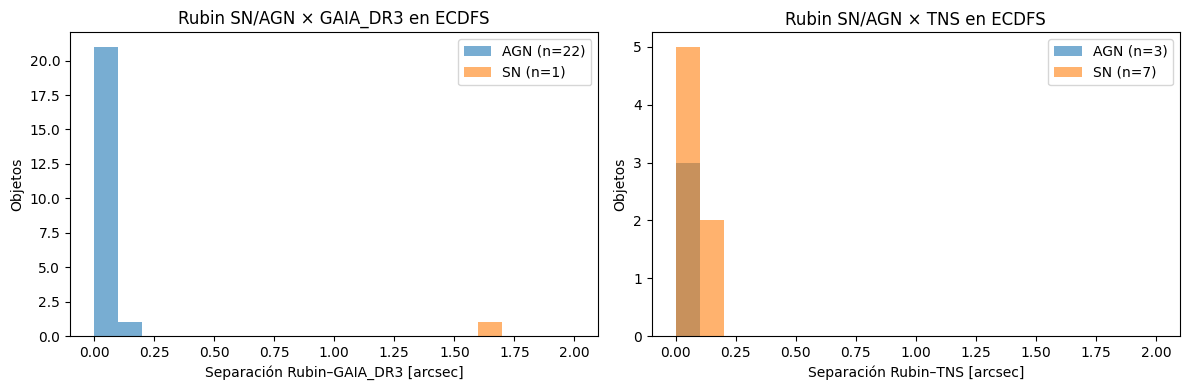

In [17]:
fig, axes = plt.subplots(1, len(xm), figsize=(6 * len(xm), 4), squeeze=False)
for ax, (name, df) in zip(axes[0], xm.items()):
    for cls in ["AGN", "SN"]:
        sep = df.loc[df["has_match"] & (df["class_name"] == cls), "_dist_arcsec"].astype(float)
        ax.hist(sep, bins=np.linspace(0, ext[name]["radius_arcsec"], 21), alpha=0.6,
                label=f"{cls} (n={len(sep)})")
    ax.set_xlabel(f"Separación Rubin–{name} [arcsec]")
    ax.set_ylabel("Objetos")
    ax.set_title(f"Rubin SN/AGN × {name} en {FIELD}")
    ax.legend()
plt.tight_layout()
plt.show()

**Verificación con Astropy**

In [18]:
def astropy_crossmatch(table_1, table_2, ra_1, dec_1, ra_2, dec_2,
                       match_radius=1.0 * u.arcsec,
                       table_names=("table1", "table2")):
    """Positional crossmatch of two Astropy Tables.
    Returns every pair within match_radius, sorted by separation."""
    coord_1 = SkyCoord(ra=np.asarray(table_1[ra_1], dtype=float) * u.deg,
                       dec=np.asarray(table_1[dec_1], dtype=float) * u.deg)
    coord_2 = SkyCoord(ra=np.asarray(table_2[ra_2], dtype=float) * u.deg,
                       dec=np.asarray(table_2[dec_2], dtype=float) * u.deg)

    idx_1, idx_2, separation, _ = coord_2.search_around_sky(coord_1, match_radius)

    if len(idx_1) == 0:
        # Sin pares dentro del radio: astropy.join no acepta tablas vacías
        print(f"Sin matches dentro de {match_radius}.")
        return Table()

    matched_1 = table_1[idx_1].copy()
    matched_2 = table_2[idx_2].copy()

    match_id = np.arange(len(idx_1), dtype=int)
    matched_1["match_id"] = match_id
    matched_2["match_id"] = match_id
    matched_1["separation_arcsec"] = separation.to_value(u.arcsec)

    crossmatch = join(matched_1, matched_2, keys="match_id", join_type="inner",
                      table_names=list(table_names),
                      uniq_col_name="{col_name}_{table_name}")
    crossmatch.sort("separation_arcsec")
    return crossmatch

In [19]:
table_1 = Table.from_pandas(df_rubin)
xm_astropy = {}

for name, e in ext.items():
    df_ext = to_pandas(e["cat"].compute())
    # Para verificar el match basta con columnas numéricas (evita problemas con texto/anidadas)
    df_ext = df_ext.select_dtypes(include="number")
    table_2 = Table.from_pandas(df_ext)

    res = astropy_crossmatch(table_1, table_2, "meanra", "meandec", e["ra"], e["dec"],
                             match_radius=e["radius_arcsec"] * u.arcsec,
                             table_names=("rubin", e["suffix"].lstrip("_")))
    xm_astropy[name] = res
    n_astropy = len(set(res["oid"])) if len(res) else 0
    n_lsdb = xm[name].loc[xm[name]["has_match"], "oid"].nunique()
    print(f"{name}: {len(df_ext):,} fuentes en el campo | "
          f"objetos con match → Astropy: {n_astropy}, LSDB: {n_lsdb}")

Computing Catalog:   0%|          | 0/4 [00:00<?, ?it/s]

GAIA_DR3: 35,266 fuentes en el campo | objetos con match → Astropy: 23, LSDB: 23


Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

TNS: 264 fuentes en el campo | objetos con match → Astropy: 10, LSDB: 10


**SN con TNS: transitorios reportados**

In [20]:
def find_col(columns, candidates):
    for c in candidates:
        for variant in (c, f"{c}_tns"):
            if variant in columns:
                return variant
    return None

if "TNS" in xm:
    tns = (xm["TNS"][xm["TNS"]["has_match"]]
           .sort_values("_dist_arcsec").drop_duplicates("oid").copy())
    cols = tns.columns
    TNS_NAME = find_col(cols, ["name", "objname", "fullname", "name_prefix"])
    TNS_TYPE = find_col(cols, ["type", "obj_type", "objtype", "classification"])
    TNS_Z = find_col(cols, ["redshift", "z"])
    TNS_DATE = find_col(cols, ["discoverydate", "discovery_date", "disc_date"])
    print("Columnas TNS detectadas:", dict(nombre=TNS_NAME, tipo=TNS_TYPE, z=TNS_Z, fecha=TNS_DATE))

    show = ["oid", "class_name", "probability", "_dist_arcsec"] + \
           [c for c in (TNS_NAME, TNS_TYPE, TNS_Z, TNS_DATE) if c]
    display(tns[show].sort_values(["class_name", "_dist_arcsec"]))

Columnas TNS detectadas: {'nombre': 'name_tns', 'tipo': 'type_tns', 'z': 'redshift_tns', 'fecha': 'discoverydate_tns'}


,oid,class_name,probability,_dist_arcsec,name_tns,type_tns,redshift_tns,discoverydate_tns
9,313677517048250401,AGN,0.912463,0.01823,2025amzi,<NA>,<NA>,2025-07-29 07:59:06.967
8,313756671181062188,AGN,0.902658,0.022604,2025amzf,<NA>,<NA>,2025-07-29 07:59:06.967
7,313756671195217941,AGN,0.943,0.085315,2025alrt,<NA>,<NA>,2025-11-18 20:37:40.000
1,313928193953234970,SN,0.685611,0.003441,2026fbw,<NA>,<NA>,2026-01-01 05:16:58.000
5,313879818462560268,SN,0.806942,0.007878,2025amka,<NA>,<NA>,2025-12-21 06:52:10.000
4,313994139532263447,SN,0.972766,0.013825,2026eqf,SN IIn,0.147,2026-01-16 02:50:50.653
2,313853499427782700,SN,0.869342,0.026582,2025alvs,<NA>,<NA>,2025-12-15 03:27:42.000
3,313835835598831657,SN,0.98445,0.083974,2025alry,<NA>,<NA>,2025-11-27 03:17:13.344
6,313756671570083932,SN,0.865914,0.1373,2025alrv,<NA>,<NA>,2025-11-21 04:28:00.768
0,313699514821640259,SN,0.965387,0.153674,2025aijl,<NA>,<NA>,2025-12-24 07:49:30.720


In [24]:
# Clase de Rubin vs. tipo en TNS
if "TNS" in xm and len(tns) and TNS_TYPE:
    tipo = tns[TNS_TYPE].astype("string").fillna("sin clasificar")
    tipo = tipo.where(tipo.str.strip() != "", "sin clasificar")
    display(pd.crosstab(tns["class_name"], tipo, margins=True))

type_tns,SN IIn,sin clasificar,All
class_name,,,
AGN,0,3,3
SN,1,6,7
All,1,9,10
